In [ ]:
import nbformat as nbf
import os

# Loop through lecture numbers 1 to 15
for i in range(1, 16):
    input_filename = f'EECS253_2025_Lecture{i}.ipynb'
    output_filename = f'EECS253_2025_Lecture{i}.ipynb'
    
    # Check if the file exists to avoid errors
    if os.path.exists(input_filename):
        with open(input_filename, 'r', encoding='utf-8') as f:
            ntbk = nbf.read(f, as_version=4)

        # Filter: Keep ONLY 'code' cells (removes all markdown/text blocks)
        ntbk.cells = [cell for cell in ntbk.cells if cell.cell_type == 'code']

        # Save the cleaned notebook
        with open(output_filename, 'w', encoding='utf-8') as f:
            nbf.write(ntbk, f)
            
        print(f"Processed: {input_filename} -> {output_filename}")
    else:
        print(f"Skipped: {input_filename} (File not found)")


Processed: EECS253_2025_Lecture1.ipynb -> markdown_only_notebook_1.ipynb
Processed: EECS253_2025_Lecture2.ipynb -> markdown_only_notebook_2.ipynb
Processed: EECS253_2025_Lecture3.ipynb -> markdown_only_notebook_3.ipynb
Processed: EECS253_2025_Lecture4.ipynb -> markdown_only_notebook_4.ipynb
Processed: EECS253_2025_Lecture5.ipynb -> markdown_only_notebook_5.ipynb
Processed: EECS253_2025_Lecture6.ipynb -> markdown_only_notebook_6.ipynb
Processed: EECS253_2025_Lecture7.ipynb -> markdown_only_notebook_7.ipynb
Processed: EECS253_2025_Lecture8.ipynb -> markdown_only_notebook_8.ipynb
Processed: EECS253_2025_Lecture9.ipynb -> markdown_only_notebook_9.ipynb
Processed: EECS253_2025_Lecture10.ipynb -> markdown_only_notebook_10.ipynb
Processed: EECS253_2025_Lecture11.ipynb -> markdown_only_notebook_11.ipynb
Processed: EECS253_2025_Lecture12.ipynb -> markdown_only_notebook_12.ipynb
Processed: EECS253_2025_Lecture13.ipynb -> markdown_only_notebook_13.ipynb
Skipped: EECS253_2025_Lecture14.ipynb (File

In [28]:
#this is called "magic". It is not really necessary, but good because someday there will be tensorflow3
%tensorflow_version 2.x

Colab only includes TensorFlow 2.x; %tensorflow_version has no effect.


In [29]:
#You will use these basic imports for everything
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [30]:
#Useful for this example
from matplotlib.dates import DateFormatter

In [31]:
#Here is an example (copied from online somewhere) of using explicit time values. Pandas has functions for this.
rng=pd.date_range('2021-03-24','2021-09-01',freq='D')  #freq='D' means each step is one day
ts = pd.Series(np.random.randn(len(rng)),index=rng)  #a pandas Series is not the same as an Array or a DataFrame
ts

,0
2021-03-24,0.464515
2021-03-25,-0.159521
2021-03-26,-0.297688
2021-03-27,0.189125
2021-03-28,1.183942
...,...
2021-08-28,-0.501791
2021-08-29,0.371907
2021-08-30,-0.999565
2021-08-31,0.796320


In [32]:
#turn the series into a pandas dataframe
df = pd.DataFrame({'date':rng,'val':ts})
df

,date,val
2021-03-24,2021-03-24,0.464515
2021-03-25,2021-03-25,-0.159521
2021-03-26,2021-03-26,-0.297688
2021-03-27,2021-03-27,0.189125
2021-03-28,2021-03-28,1.183942
...,...,...
2021-08-28,2021-08-28,-0.501791
2021-08-29,2021-08-29,0.371907
2021-08-30,2021-08-30,-0.999565
2021-08-31,2021-08-31,0.796320


In [33]:
#load csv file into a pandas dataframe
pollution = pd.read_csv(
'https://raw.githubusercontent.com/owid/owid-datasets/master/datasets/Air%20pollution%20by%20city%20-%20Fouquet%20and%20DPCC%20(2011)/Air%20pollution%20by%20city%20-%20Fouquet%20and%20DPCC%20(2011).csv' )
#column names are too long to be useful, so we can change them
pollution = pollution.rename(
columns={
'Suspended Particulate Matter (SPM) (Fouquet and DPCC (2011))' : 'SPM' ,
'Smoke (Fouquet and DPCC (2011))' : 'Smoke' ,
'Entity' : 'City' }
)
#look at the dataframe; by default shows the first and last lines of the table
pollution


,City,Year,Smoke,SPM
0,Delhi,1997,NaN,363.0
1,Delhi,1998,NaN,378.0
2,Delhi,1999,NaN,375.0
3,Delhi,2000,NaN,431.0
4,Delhi,2001,NaN,382.0
...,...,...,...,...
326,London,2012,NaN,17.0
327,London,2013,NaN,17.0
328,London,2014,NaN,17.0
329,London,2015,NaN,15.0


In [34]:
#can explore this here, although it's always worthwhile to just open the data in excel or numbers or something
pollution.City.unique()


array(['Delhi', 'London'], dtype=object)

In [35]:
#basic descriptive statistics.  Note that it does not understand that Year is a date value
#  they apparently have pollution data going back to 1700 in London
pollution.describe()

,Year,Smoke,SPM
count,331.000000,301.000000,331.000000
mean,1864.154079,210.296440,365.970050
std,94.366037,88.543288,172.512674
min,1700.000000,13.750000,15.000000
25%,1782.500000,168.571429,288.474026
50%,1865.000000,208.214286,375.324675
75%,1947.500000,291.818182,512.609209
max,2016.000000,342.857143,623.376623


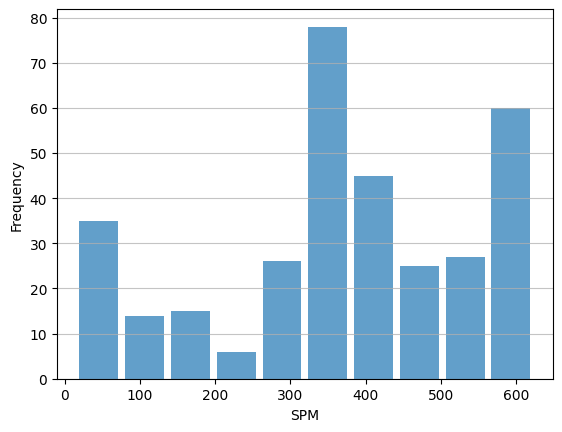

In [36]:
n, bins, patches = plt.hist(x=pollution[ 'SPM' ], bins= 'auto' ,alpha= 0.7 , rwidth= 0.85 )
plt.grid(axis= 'y' , alpha= 0.75 )
plt.xlabel( 'SPM' )
plt.ylabel( 'Frequency' );  #just like matlab, semicolon prevents output from being displayed

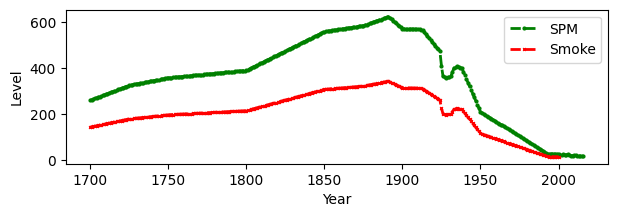

In [37]:
London_index = pollution['City']=='London'  #select only the london data
#the following are equivalent:
#plt.plot(pollution[London_index]['Year'],pollution[London_index]['SPM'])  #explicit plt.plot(x,y)
#plt.plot('Year','SPM',data = pollution[London_index])   #plot.plot(column1, column2, data = fromdatasource)
#pollution[London_index].plot('Year','SPM')    #pandas makes plot a method of the dataframe
#how to make it fancy
axes = plt.gca()  #you need this to make all the plots overlay on the same graph
pollution[London_index].plot('Year','SPM',color='green', marker='o', linestyle='dashed',
      linewidth=2, markersize=2,figsize=( 7 , 2 ),ax = axes)
pollution[London_index].plot('Year','Smoke',color='red', marker='x', linestyle='dashed',
      linewidth=2, markersize=2,figsize=( 7 , 2 ),ax=axes)
plt.ylabel('Level')
plt.show()

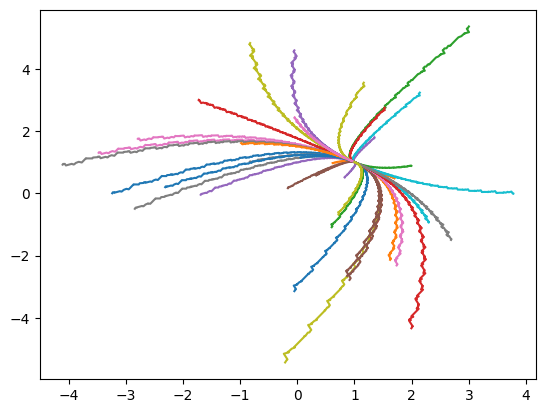

array([[1.0000974 , 0.99992265]])

In [38]:
#Simple example of linear learning
npoints = 20  #the number of examples
x = np.random.randn(2,npoints)  #these are the input examples, chosen randomly
f = np.sum(x,axis=0)   #the right answer is just the sum

for trials in range(1,40):  #try this for many different initial weights
  w = 2*np.random.randn(2)  #choose a random initial set of weights
  w = w.reshape(1,2)        #python weirdness: change the vector into a 1D array
  wvals = w                 #going to save all the weights along the way
  gamma = 0.01              #learning rate.  Batch size is 1 here.
  for i in range(1,100):
    for n in range(npoints):
      delta = np.dot(w,x[:,n]) - f[n]  #the error for this example
      w = w - gamma * delta * x[:,n]   #gradient descent learning rule
      wvals = np.append(wvals,w,axis=0)    #save the weights

  plt.plot(wvals[:,0],wvals[:,1])  #plot the learning for this trial
plt.show()   #plot all the trials for all the different initial weights
w

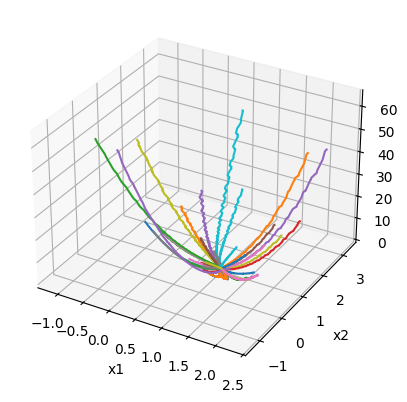

In [39]:
#same thing for 3D plot showing the cost function
from mpl_toolkits import mplot3d
fig = plt.figure()
ax = plt.axes(projection='3d')

npoints = 20  #the number of examples
x = np.random.randn(2,npoints)  #these are the input examples, chosen randomly
f = np.sum(x,axis=0)   #the right answer is just the sum

for trials in range(1,40):  #try this for many different initial weights
  w = np.random.randn(2)+[1,1]  #choose a random initial set of weights
  w = w.reshape(1,2)        #python weirdness: change the vector into a 1D array
  J = np.sum(np.square(np.matmul(w,x) - f)/2.0)

  wvals = w                 #going to save all the weights along the way
  jvals = J
  gamma = 0.01              #learning rate
  for i in range(1,100):
    for n in range(npoints):
      delta = np.dot(w,x[:,n]) - f[n]  #the error for this example
      w = w - gamma * delta * x[:,n]   #gradient descent learning rule
      J = np.sum(np.square(np.matmul(w,x) - f)/2.0)

      wvals = np.append(wvals,w,axis=0)    #save the weights
      jvals = np.append(jvals,J)

  plt.plot(wvals[:,0],wvals[:,1],jvals)  #plot the learning for this trial
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('J');
plt.show();   #plot all the trials for all the different initial weights


In [40]:
#Lets do the same thing using Keras
#first, build the network
import keras

model = keras.Sequential()
model.add(keras.Input(shape=(2,)))  #shape is a 2-element flat vector (one row of input matrix)
model.add(keras.layers.Dense(1,use_bias=False))  #make this a simple linear model
model.summary()
opt = keras.optimizers.Adam(learning_rate = 0.01)
model.compile(optimizer=opt, loss = 'mse')

#now, train the network
npoints = 100  #the number of examples
x = np.random.randn(npoints,2)  #these are the input examples, chosen randomly
y = np.sum(x,axis=1)   #the right answer is just the sum
model.fit(x,y,epochs=10,batch_size=1)

#see if it learned
print(model.weights[0][:])

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.8129
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1775
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0196
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0010
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.5358e-05
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.6674e-07
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0493e-09
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0805e-12
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.6056e-13
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.6056e-13
tf.Tensor(
[[1.       ]
 [0.9999995]], shape=(2, 1), dtype=float32)


<Axes: >

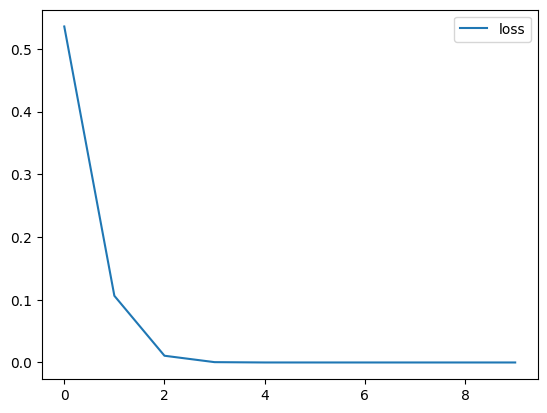

In [41]:
#look at the cost function for each epoch
losses = pd.DataFrame(model.history.history)
losses.plot()

In [42]:
#BAD EXAMPLE:  Multilayer linear network
import keras

model = keras.Sequential()
model.add(keras.Input(shape=(2,)))  #shape is a 2-element flat vector (one row of input matrix)
model.add(keras.layers.Dense(2,use_bias=False))  #make this a simple linear model
model.add(keras.layers.Dense(1,use_bias=False))  #make this a simple linear model
model.summary()
opt = keras.optimizers.Adam(learning_rate = 0.01)
model.compile(optimizer=opt, loss = 'mse')

#now, train the network
npoints = 100  #the number of examples
x = np.random.randn(npoints,2)  #these are the input examples, chosen randomly
y = np.sum(x,axis=1)   #the right answer is just the sum
model.fit(x,y,epochs=10,batch_size=1)

#see if it learned
W2 = model.weights[0][:].numpy()
W1 = model.weights[1][:].numpy()
print(W2)
print(W1)
print(W1.T@W2.T)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 2)              │             4 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6 (24.00 B)

 Trainable params: 6 (24.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0213
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.0476e-05
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.9537e-07
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6151e-08
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.5203e-11
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.8840e-13
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2734e-14
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.2825e-15
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5.5286e-14
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 9.8244e-13
[[-0.9956191   0.52856266]
 [-0.5532552   0.72769535]]
[[-0.46087277]
 [ 1.0238072 ]]
[[1. 1.]]


<Axes: >

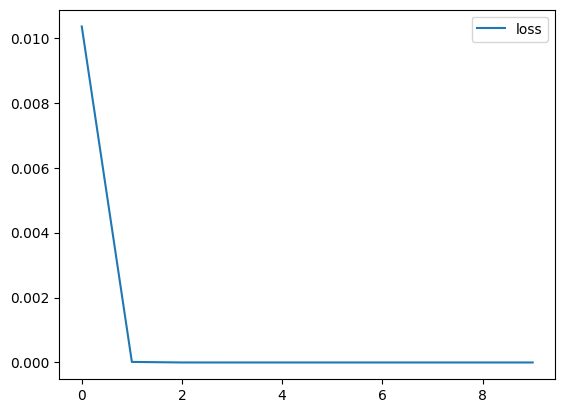

In [43]:
losses = pd.DataFrame(model.history.history)
losses.plot()

In [44]:
from sklearn.datasets import fetch_openml
eeg = fetch_openml(data_id=1471,as_frame= True )  #returns a dataframe
#URL for the dataset: https://openml.org/search?type=data&status=active&id=1471
#this timeseries dataset does not actually include time.  So we will synthesize timestamps
max_time = 117
num_eeg_points = len(eeg['data'])
increment = max_time / num_eeg_points
index = np.linspace(start=0, stop=max_time, num=num_eeg_points)
ts_index = pd.to_datetime(index, unit= 's' ,origin = '2022-1-3 15:30:00')  #convert to seconds
#note that all dates start at january 1, 1970, unless you specify a different origin
v1 = pd.Series(name= 'V1' , data=eeg[ 'data' ][ 'V1' ].values, index=ts_index)  #turns the dataframe into a Series
v1

,V1
2022-01-03 15:30:00.000000000,4329.23
2022-01-03 15:30:00.007810831,4324.62
2022-01-03 15:30:00.015621901,4327.69
2022-01-03 15:30:00.023432732,4328.72
2022-01-03 15:30:00.031243801,4326.15
...,...
2022-01-03 15:31:56.968756199,4281.03
2022-01-03 15:31:56.976567268,4276.92
2022-01-03 15:31:56.984378099,4277.44
2022-01-03 15:31:56.992189169,4284.62


In [45]:
# there is an artifact at 1:10, so select a slice of time before
# what artifact, need to check?
slicing = (v1.index >= '2022-1-3 15:30:08' ) & (v1.index <= '2022-1-3 15:31:10.000000000' )
#the result is still a pandas series, with timestamp, value pairs.
v1[slicing]

,V1
2022-01-03 15:30:08.006208658,4289.74
2022-01-03 15:30:08.014019728,4284.10
2022-01-03 15:30:08.021830559,4280.00
2022-01-03 15:30:08.029641390,4289.74
2022-01-03 15:30:08.037452459,4298.46
...,...
2022-01-03 15:31:09.962547541,4289.74
2022-01-03 15:31:09.970358610,4283.08
2022-01-03 15:31:09.978169441,4284.62
2022-01-03 15:31:09.985980272,4289.23


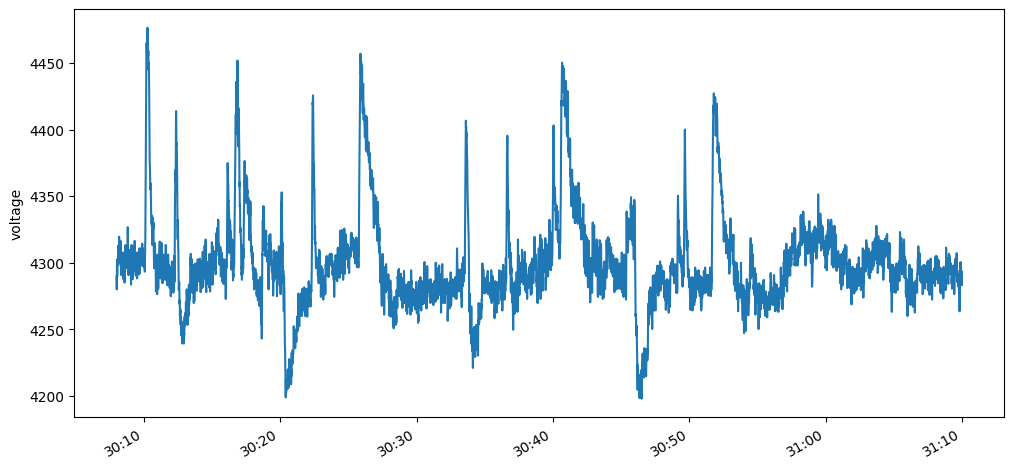

In [46]:
#show the eeg data from channel v1
date_formatter = DateFormatter( "%M:%S" )  #just show minutes:seconds
ax = v1[slicing].plot(figsize=( 12 , 6 ))
ax.xaxis.set_major_formatter(date_formatter)
plt.ylabel( 'voltage' );

<Axes: >

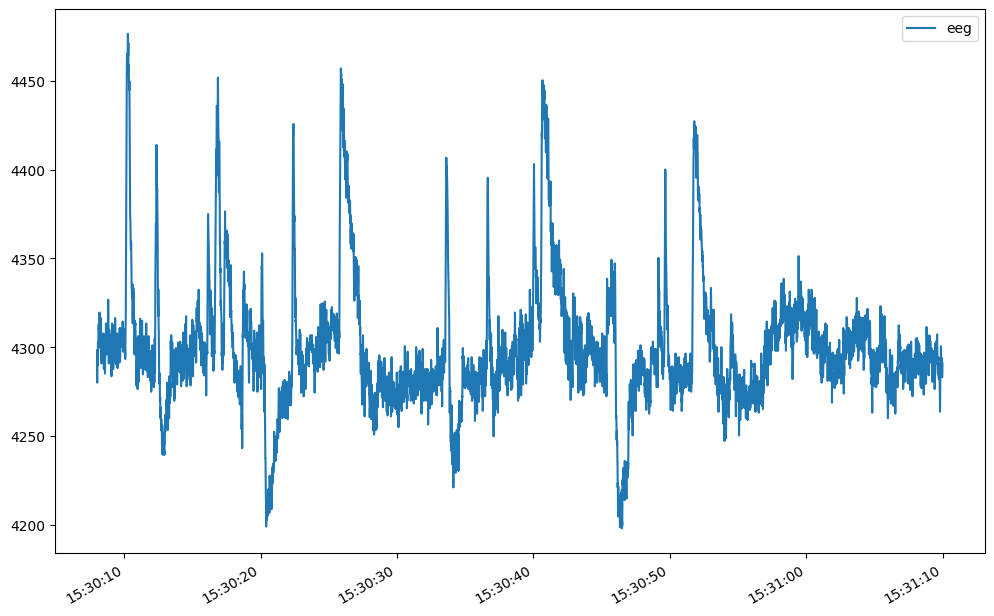

In [47]:
#make a dataframe from the slice
df = v1[slicing].to_frame(name="eeg")
df.plot(figsize=(12,8))

In [48]:
#will attempt to predict the last test_size elements in the series
#The last test_size elements are the test set.  Everything else is the training set
test_size = 180
test_ind = len(df)-test_size  #index of the first element to predict -1
train=df.iloc[:test_ind]  #train on everything before that
test=df.iloc[test_ind:]   #test on everything after that

In [49]:
print(len(df))
print(test_ind)

7937
7757


In [50]:
#scale the range
# this is really important so that the inputs to the network are between about -1 and +1
#  that keeps the data from saturating the nonlinearities in the network.
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(train)
scaled_train = scaler.transform(train)
scaled_test = scaler.transform(test)  #scale the test set using the training set scaler
                                      #(because we don't know the test set beforehand)
                                      #NOTE: scaler.transform() returns a numpy array, even for dataframe input

In [51]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = 12
generator = TimeseriesGenerator(scaled_train, scaled_train, length = predict_length, batch_size=1)
#X,y = generator[t] produces an array {[X(t-N)...X(t-1)], [X(t)]}

In [52]:
##First, lets start with a linear network, which will learn a linear filter
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

n_features = 1  #this is the dimension of each sample x(t)
model = Sequential()  #method to build the network from the bottom, one layer at a time
#if you don't flatten, will get a separate single-input net for each time value
model.add(Flatten(input_shape = (predict_length, n_features)))  #defines the shape of the input
model.add(Dense(1))  #single output linear unit is the top layer
model.compile(optimizer='adam', loss='mse')  #specify the cost function and the descent rule
model.summary()  #show the model layer sizes

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

In [53]:
model.fit(generator,epochs=5)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 0.0029
Epoch 2/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 8.7118e-04
Epoch 3/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 7.8340e-04
Epoch 4/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 6.4401e-04
Epoch 5/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 5.7663e-04


<Axes: >

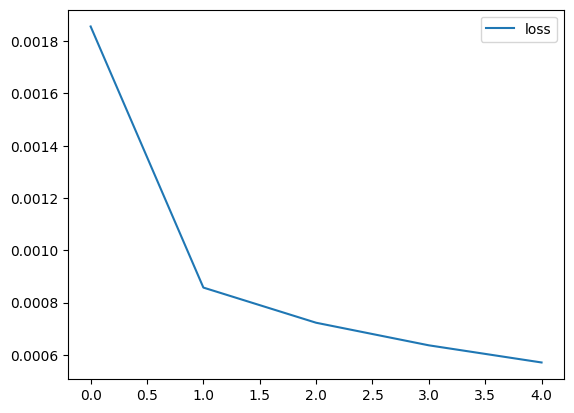

In [54]:
losses = pd.DataFrame(model.history.history)
losses.plot()

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


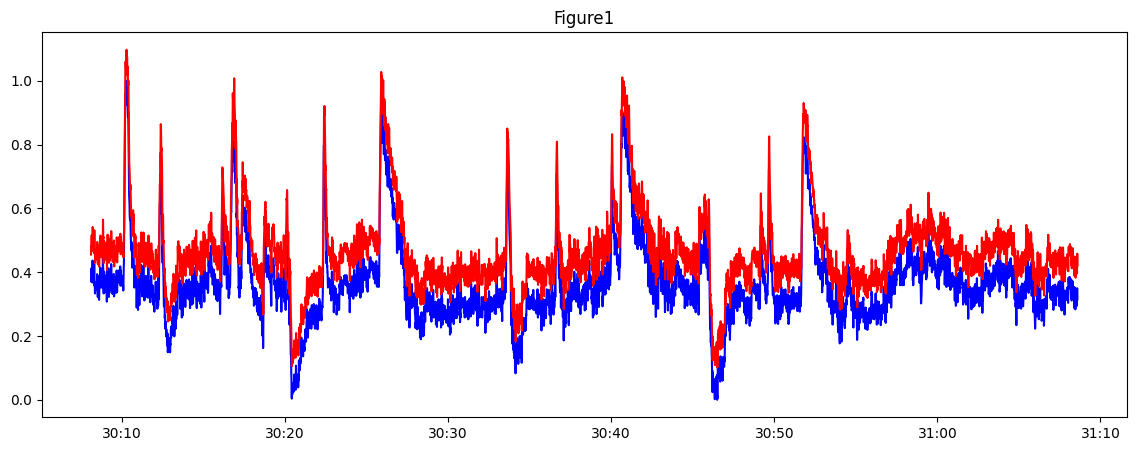

In [55]:
#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b')
plt.plot(train_predict+0.1,'r')
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


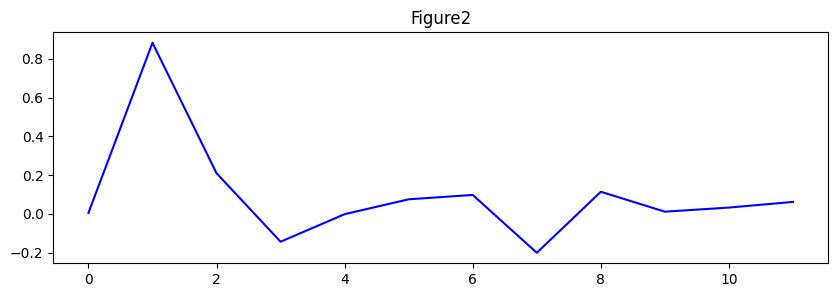

In [56]:
#calculate the impulse response
impulse = np.zeros((2*predict_length,1))  #NOTE: this is a 2D tensor of width 1
impulse[predict_length]=1
impulse_generator = TimeseriesGenerator(impulse,impulse, length = predict_length, batch_size=1)
impulse_response = model.predict(impulse_generator)
plt.figure(figsize=(10,3),linewidth=1)
plt.title('Figure2')
plt.plot(impulse_response,'b')
plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 20)             │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 701 (2.74 KB)

 Trainable params: 701 (2.74 KB)

 Non-trainable params: 0 (0.00 B)

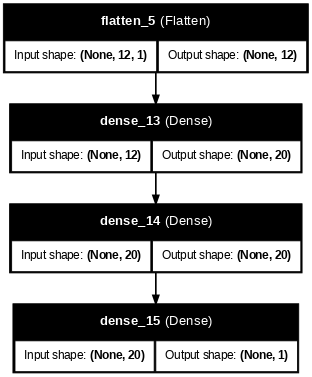

In [57]:
##Here is a simple nonlinear network.  Three-layers, with a ReLu nonlinearity
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from keras.utils import plot_model

n_features = 1  #this is the dimension of each sample x(t)
model = Sequential()  #method to build the network from the bottom, one layer at a time
#if you don't flatten, will get a separate single-input net for each time value
model.add(Flatten(input_shape = (predict_length, n_features)))  #defines the shape of the input
model.add(Dense(20, activation = 'relu'))  #20 ReLu nonlinear hidden units is the next layer
#20 * 13 [12 predict length + 1 output layer]= 260 dense_27 relu layer

model.add(Dense(20, activation = 'relu'))  #20 ReLu nonlinear hidden units is the next layer
model.add(Dense(1))  #single output linear unit is the top layer
model.compile(optimizer='adam', loss='mse')  #specify the cost function and the descent rule
model.summary()  #show the model layer sizes
plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)  #show a picture of the network

In [58]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=2) #patience: amount of times it can be rolling before reaching the minima [error]
validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

In [59]:
#for all homework, please set the seeds of your random number generators to your UCI ID number
## UCI Student ID: 37509116
np.random.seed(37509116)
tf.random.set_seed(37509116)

model.fit(generator,epochs=8,
                    validation_data=validation_generator,
                   callbacks=[early_stop])

Epoch 1/8
7737/7745 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0011

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - loss: 0.0011 - val_loss: 5.7546e-04
Epoch 2/8
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 5.2975e-04 - val_loss: 4.1917e-04
Epoch 3/8
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 4.7501e-04 - val_loss: 1.8206e-04
Epoch 4/8
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 4.2764e-04 - val_loss: 3.0368e-04
Epoch 5/8
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 4.3503e-04 - val_loss: 1.6170e-04
Epoch 6/8
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 4.1453e-04 - val_loss: 2.0008e-04
Epoch 7/8
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 3.7618e-04 - val_loss: 2.7884e-04


<Axes: >

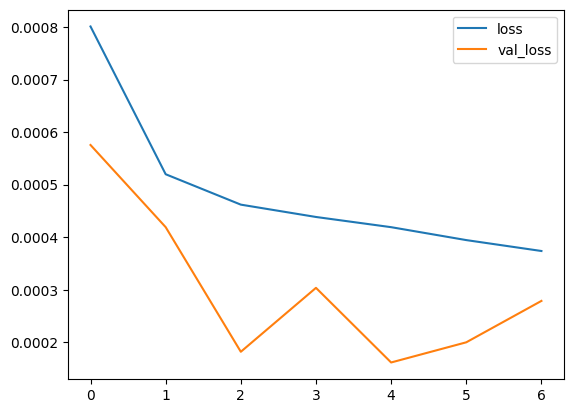

In [60]:
losses = pd.DataFrame(model.history.history)
losses.plot()

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step


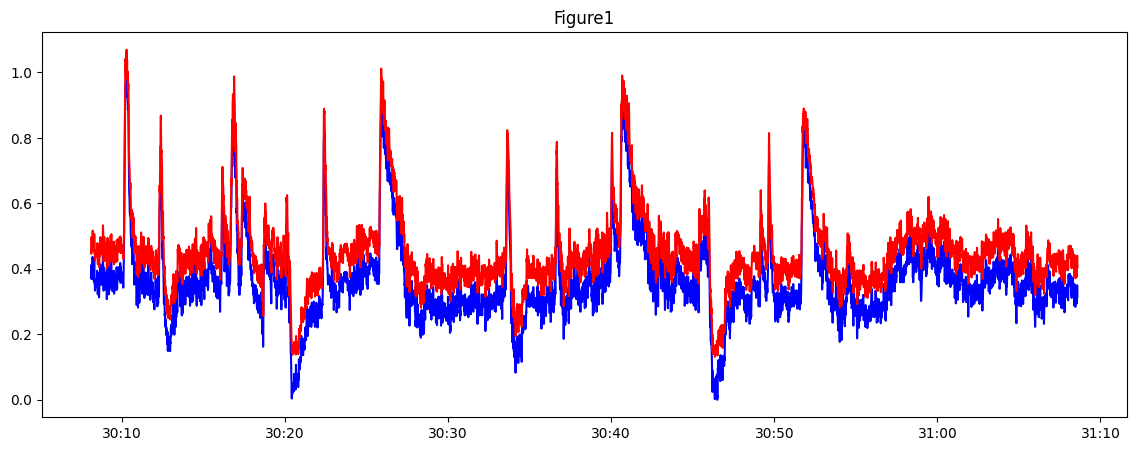

In [61]:
#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b')
plt.plot(train_predict+0.1,'r')
plt.show()


168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


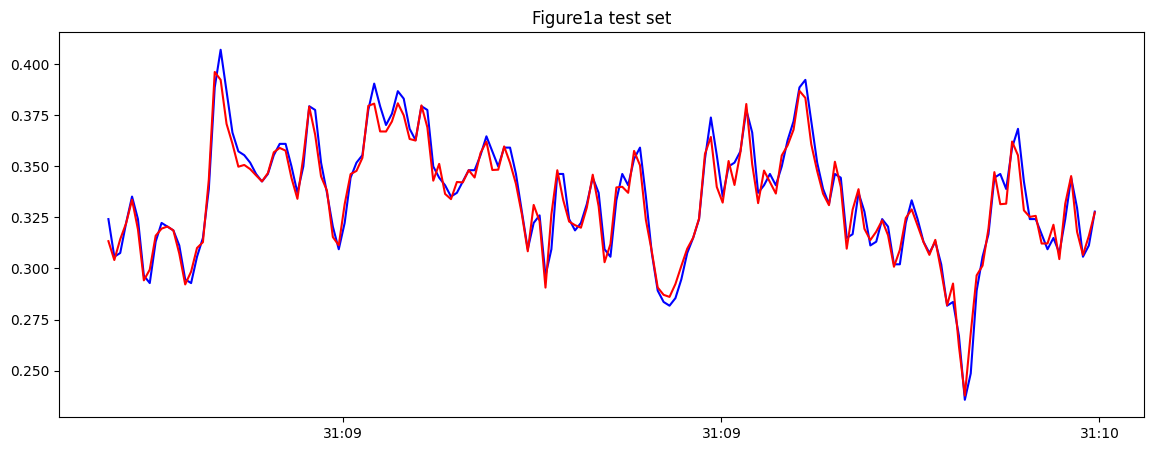

In [62]:
#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


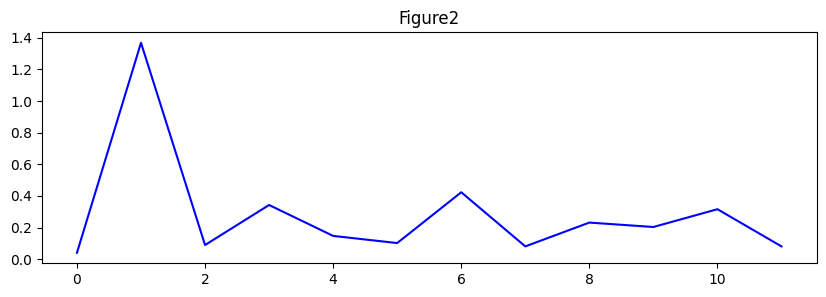

In [63]:
impulse = np.zeros((2*predict_length,1))  #NOTE: this is a 2D tensor of width 1
impulse[predict_length]=1
impulse_generator = TimeseriesGenerator(impulse,impulse, length = predict_length, batch_size=1)
impulse_response = model.predict(impulse_generator)
plt.figure(figsize=(10,3),linewidth=1)
plt.title('Figure2')
plt.plot(impulse_response,'b')
plt.show()

<Axes: title={'center': 'figure3'}>

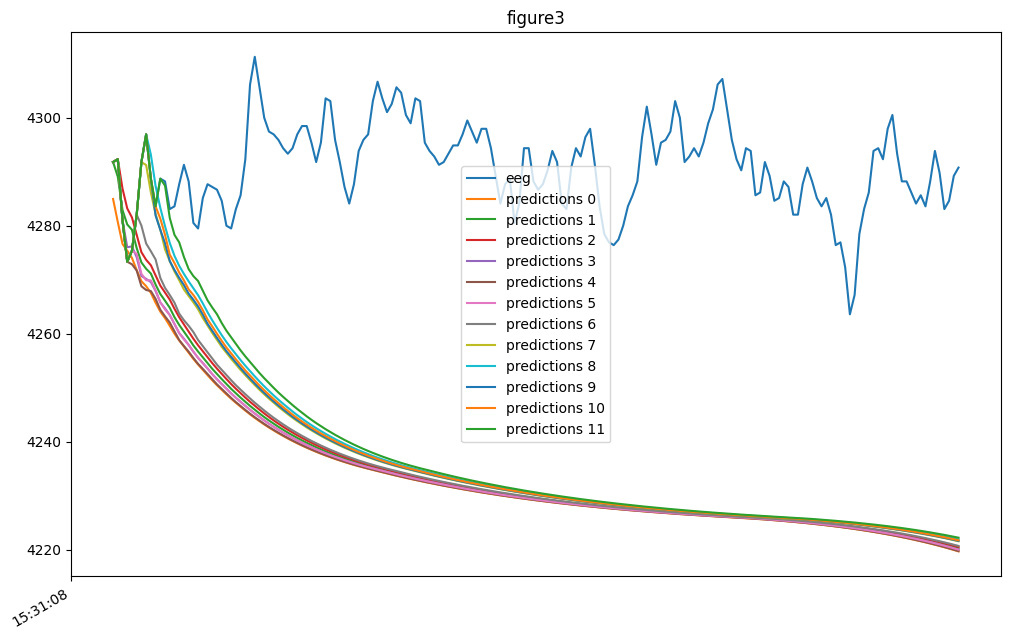

In [64]:
 test_predict = test.copy()
 for t0 in range(predict_length):
  test_predictions = []

  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):

      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='figure3')

In [65]:
#we typically use the built-in activation functions sigmoid(), relu(), LSTM(), etc...
#but you can create your own and it works fine.  When possible, use Keras "backend" functions
from keras import backend as K

def custom_activation(x):
    return (K.sigmoid(x)*K.sigmoid(x))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_6 (Flatten)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 20)             │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

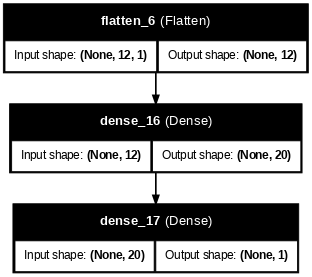

In [66]:
##Here are some options for a slightly more complicated network
from tensorflow.tools.docs.doc_controls import do_not_doc_inheritable
from matplotlib import use
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape, Flatten
from keras.utils import plot_model

n_features = 1  #this is the dimension of each sample x(t)
model = Sequential()
use_custom = 0
if use_custom == 1:
  model.add(Flatten(input_shape = (predict_length, n_features)))
  model.add(Dense(20, activation = custom_activation))
else:
  #if you don't flatten, will get a separate single-input net for each time value
  model.add(Flatten(input_shape = (predict_length, n_features)))
  model.add(Dense(20, activation = 'relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 0.0013
Epoch 2/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 6.7101e-04
Epoch 3/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 5.5213e-04
Epoch 4/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 4.9088e-04
Epoch 5/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 4.4299e-04


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 50)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,105 (8.23 KB)

 Trainable params: 701 (2.74 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,404 (5.49 KB)

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step


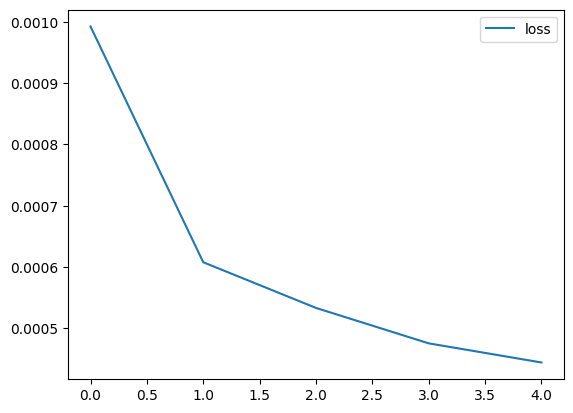

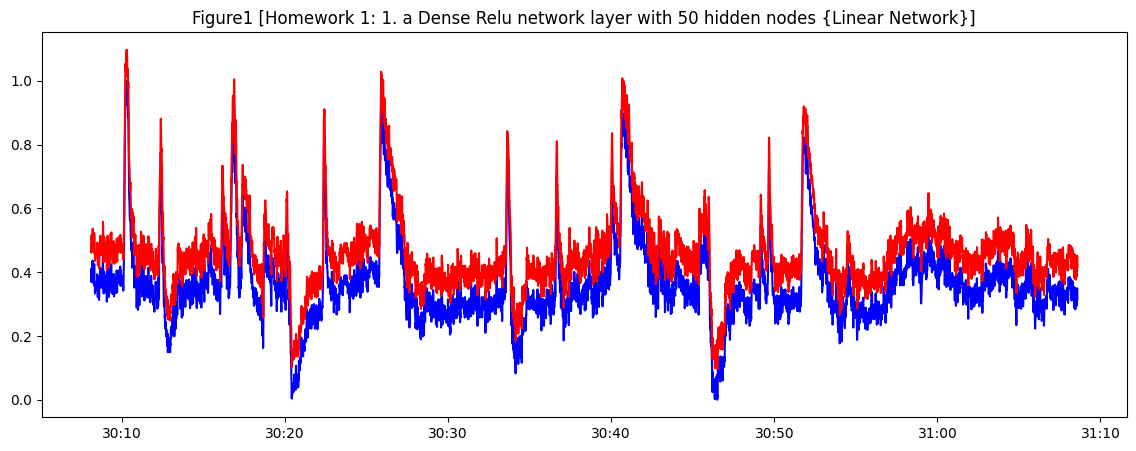

 99/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


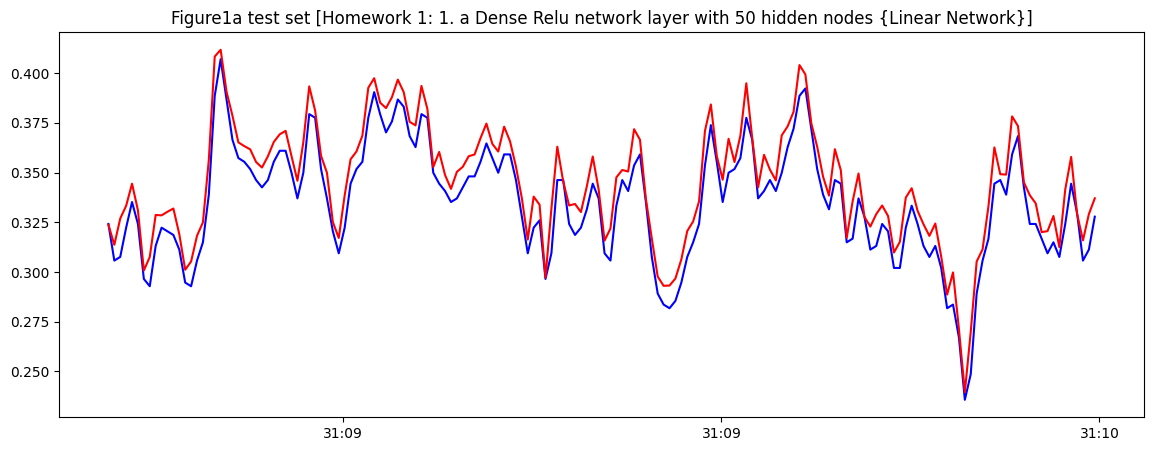

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


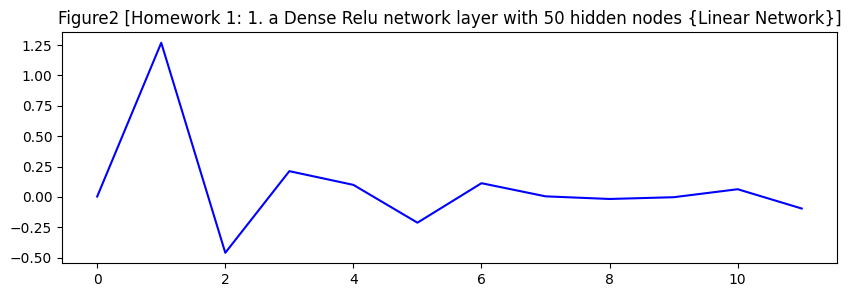

"\ntest_predict = test.copy()\nfor t0 in range(predict_length):\n  test_predictions = []\n\n  if t0>0:\n    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])\n  else:\n    first_eval_batch = scaled_train[-predict_length:]\n  current_batch = first_eval_batch.reshape((1, predict_length, n_features))\n\n  for i in range(len(test)-t0):\n\n      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])\n      current_pred = model.predict(current_batch, verbose=0)[0]\n\n      # store prediction\n      test_predictions.append(current_pred)\n\n      # update batch to now include prediction and drop first value\n      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)\n\n  if t0>0:\n    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)\n  scaled_predictions = scaler.inverse_transform(test_predictions)\n  test_predict[f'predictions {t0}']= scaled_predictions\ntest_predict.plot(figsize

In [67]:
##HomeWork 1

## 1 a Dense Relu network layer with 50 hidden nodes [linear network model]
n_features = 1  #this is the dimension of each sample x(t)
model = Sequential()
use_custom = 0
#if you don't flatten, will get a separate single-input net for each time value
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(50))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.fit(generator,epochs=5)
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

losses = pd.DataFrame(model.history.history)
losses.plot()

#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1 [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Linear Network}]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b')
plt.plot(train_predict+0.1,'r')
plt.show()

validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Linear Network}]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()


#calculating impulse response
impulse = np.zeros((2*predict_length,1))  #NOTE: this is a 2D tensor of width 1
impulse[predict_length]=1
impulse_generator = TimeseriesGenerator(impulse,impulse, length = predict_length, batch_size=1)
impulse_response = model.predict(impulse_generator)
plt.figure(figsize=(10,3),linewidth=1)
plt.title('Figure2 [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Linear Network}]')
plt.plot(impulse_response,'b')
plt.show()

"""
test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []

  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):

      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='figure3')
"""

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 0.0010
Epoch 2/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 5.7425e-04
Epoch 3/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 5.1889e-04
Epoch 4/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 4.9598e-04
Epoch 5/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 4.5181e-04


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 50)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,105 (8.23 KB)

 Trainable params: 701 (2.74 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,404 (5.49 KB)

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


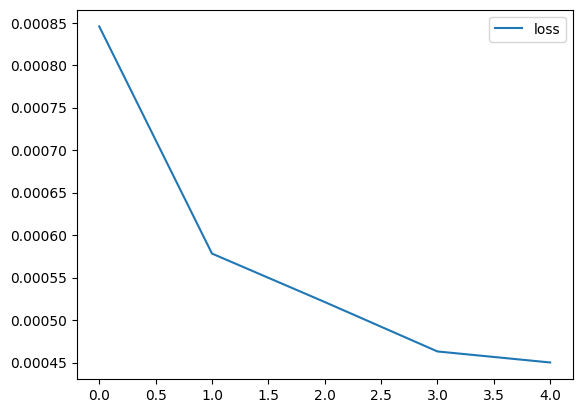

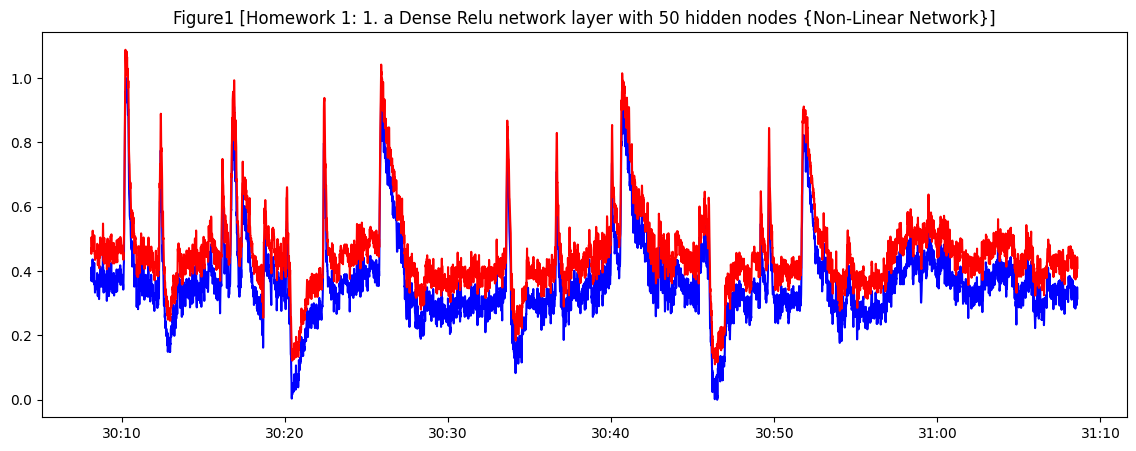

 68/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


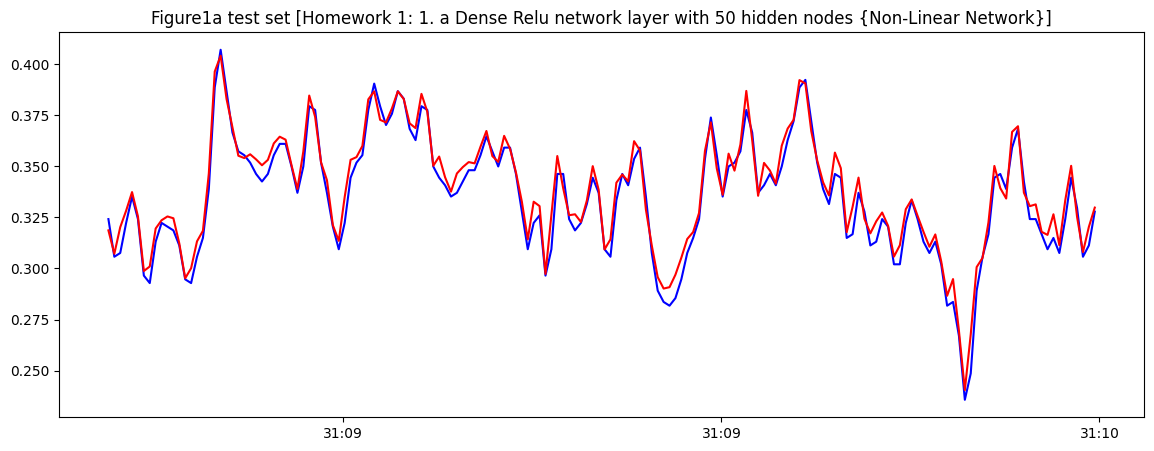

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


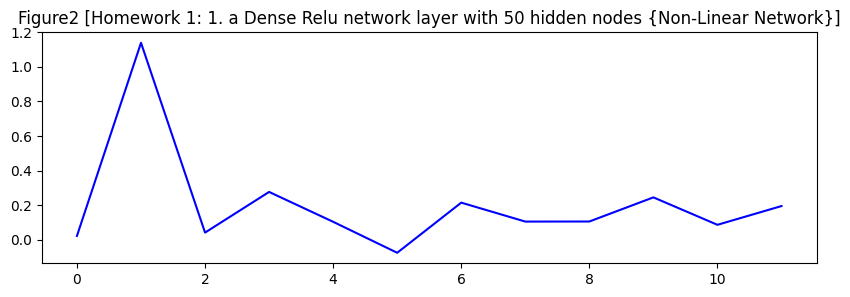

"\ntest_predict = test.copy()\nfor t0 in range(predict_length):\n  test_predictions = []\n\n  if t0>0:\n    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])\n  else:\n    first_eval_batch = scaled_train[-predict_length:]\n  current_batch = first_eval_batch.reshape((1, predict_length, n_features))\n\n  for i in range(len(test)-t0):\n\n      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])\n      current_pred = model.predict(current_batch, verbose=0)[0]\n\n      # store prediction\n      test_predictions.append(current_pred)\n\n      # update batch to now include prediction and drop first value\n      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)\n\n  if t0>0:\n    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)\n  scaled_predictions = scaler.inverse_transform(test_predictions)\n  test_predict[f'predictions {t0}']= scaled_predictions\ntest_predict.plot(figsize

In [68]:
## 1 a Dense Relu network layer with 50 hidden nodes [non-linear network model]
n_features = 1  #this is the dimension of each sample x(t)
model = Sequential()
use_custom = 0
#if you don't flatten, will get a separate single-input net for each time value
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(50, activation = 'relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.fit(generator,epochs=5)
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

losses = pd.DataFrame(model.history.history)
losses.plot()

#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1 [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Non-Linear Network}]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b')
plt.plot(train_predict+0.1,'r')
plt.show()

validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Non-Linear Network}]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()


#calculating impulse response
impulse = np.zeros((2*predict_length,1))  #NOTE: this is a 2D tensor of width 1
impulse[predict_length]=1
impulse_generator = TimeseriesGenerator(impulse,impulse, length = predict_length, batch_size=1)
impulse_response = model.predict(impulse_generator)
plt.figure(figsize=(10,3),linewidth=1)
plt.title('Figure2 [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Non-Linear Network}]')
plt.plot(impulse_response,'b')
plt.show()

"""
test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []

  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):

      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='figure3')
"""

In [69]:
print(predict_length)
print(len(test)-t0)
print(scaled_train)

12
169
[[0.32963442]
 [0.30938016]
 [0.29465632]
 ...
 [0.34988867]
 [0.320441  ]
 [0.31491058]]


<Axes: title={'center': 'Figure3 [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Non-Linear Network}]'}>

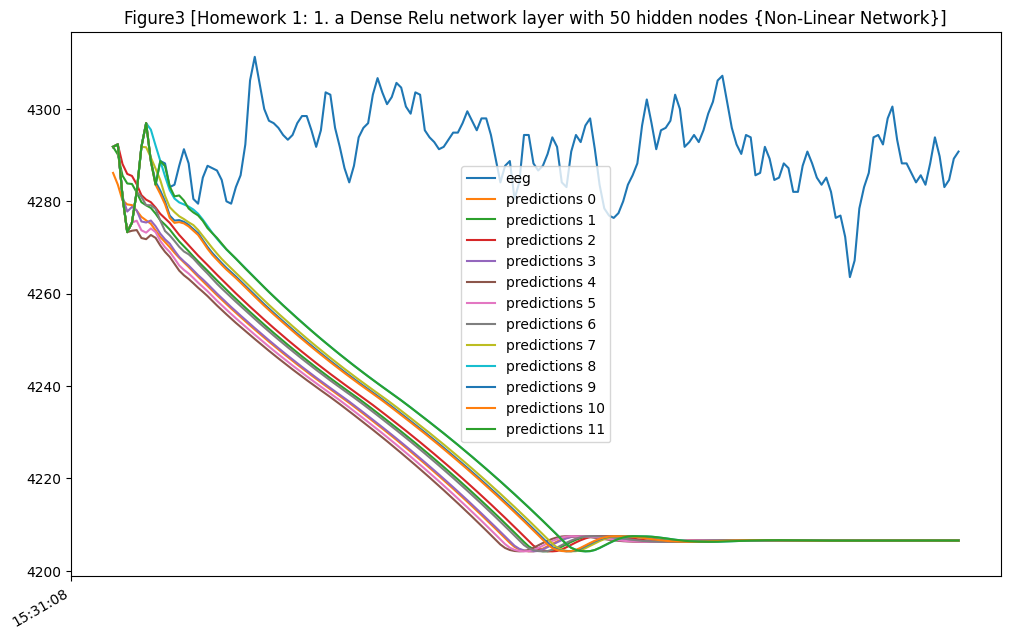

In [70]:
# took 275.677 s.
# the eeg graph is not in line with the training data, need to check
## got it: when the network is linear the eeg signals timestamps do not account for rapid shifts in signals, they are just plotted linearly across time.
test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []
  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):
      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='Figure3 [Homework 1: 1. a Dense Relu network layer with 50 hidden nodes {Non-Linear Network}]')

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 0.0016
Epoch 2/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 6.6401e-04
Epoch 3/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 5.6778e-04
Epoch 4/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 5.3857e-04
Epoch 5/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 4.9634e-04


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_9 (Flatten)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 20)             │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 845 (3.30 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 564 (2.21 KB)

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


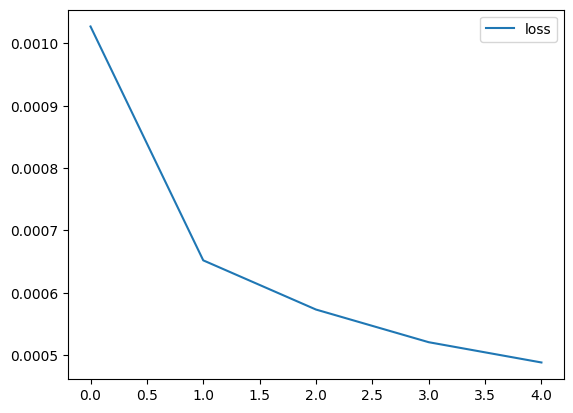

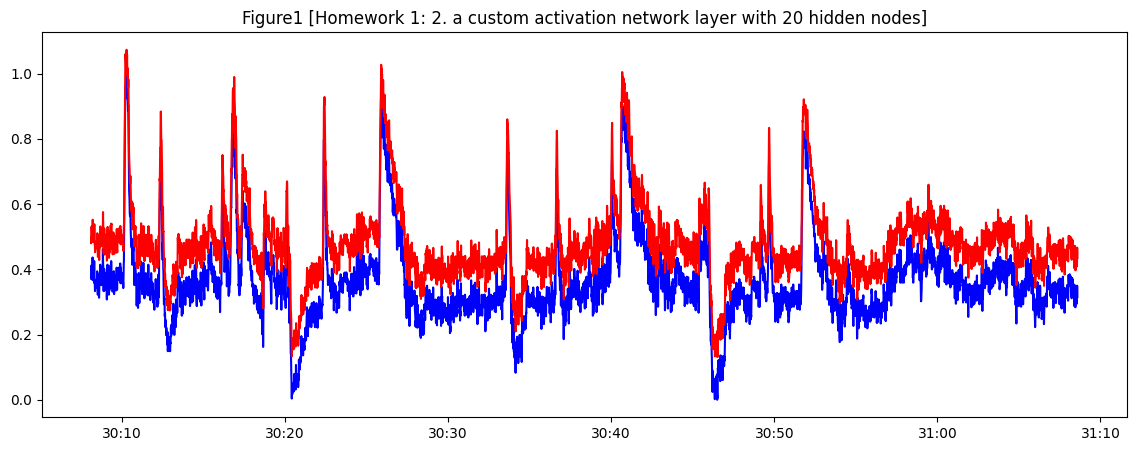

100/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


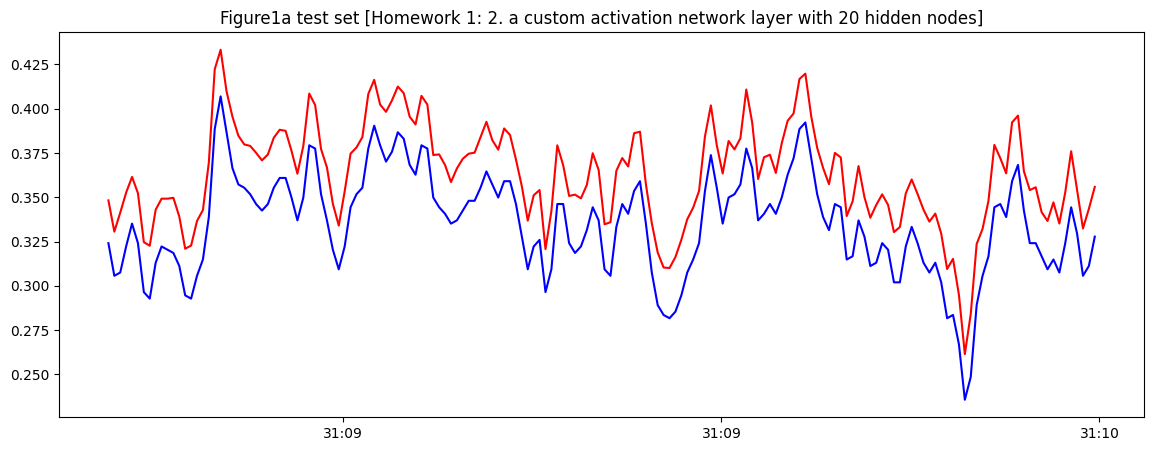

<Axes: title={'center': 'Figure3 [Homework 1: 2. a custom activation network layer with 20 hidden nodes]'}>

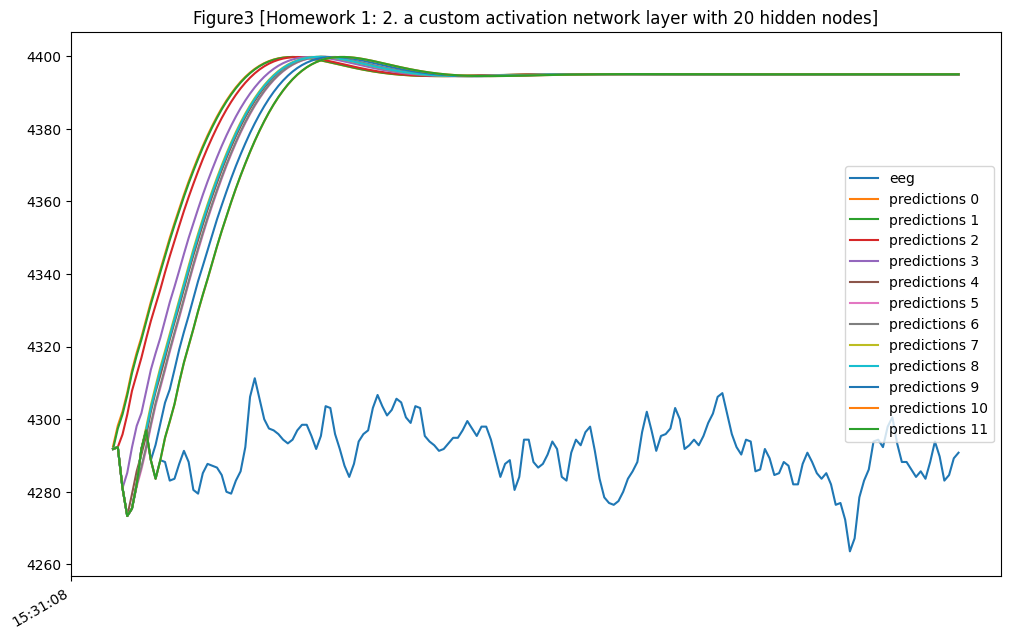

In [71]:
##HomeWork 1
## 2 a custom activation network layer with 20 hidden nodes
import tensorflow.keras.backend as K

n_features = 1
model = Sequential()
use_custom = 1
def custom_activation(x):
    return (K.sigmoid(x)*K.sigmoid(x))
if use_custom == 1:
    model.add(Flatten(input_shape=(predict_length, n_features)))
    model.add(Dense(20, activation=custom_activation))
else:
    model.add(Flatten(input_shape=(predict_length, n_features)))
    model.add(Dense(50, activation='relu'))

model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.fit(generator,epochs=5)
model.summary()

keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)  # needs pydot/graphviz installed


losses = pd.DataFrame(model.history.history)
losses.plot()

predicted_outputs = model.predict(generator)
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])

plt.figure(figsize=(14,5), linewidth=1)
plt.title('Figure1 [Homework 1: 2. a custom activation network layer with 20 hidden nodes]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig, 'b')
plt.plot(train_predict + 0.1, 'r')
plt.show()

validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set [Homework 1: 2. a custom activation network layer with 20 hidden nodes]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()


test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []
  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):
      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='Figure3 [Homework 1: 2. a custom activation network layer with 20 hidden nodes]')

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 0.0057
Epoch 2/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 6.5710e-04
Epoch 3/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 5.2938e-04
Epoch 4/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 4.7390e-04
Epoch 5/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 4.3335e-04


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 50)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,105 (8.23 KB)

 Trainable params: 701 (2.74 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,404 (5.49 KB)

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


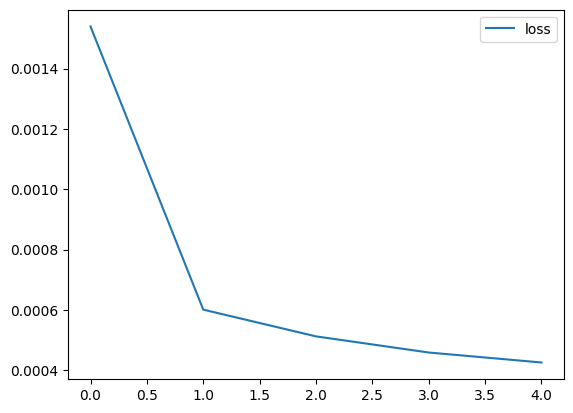

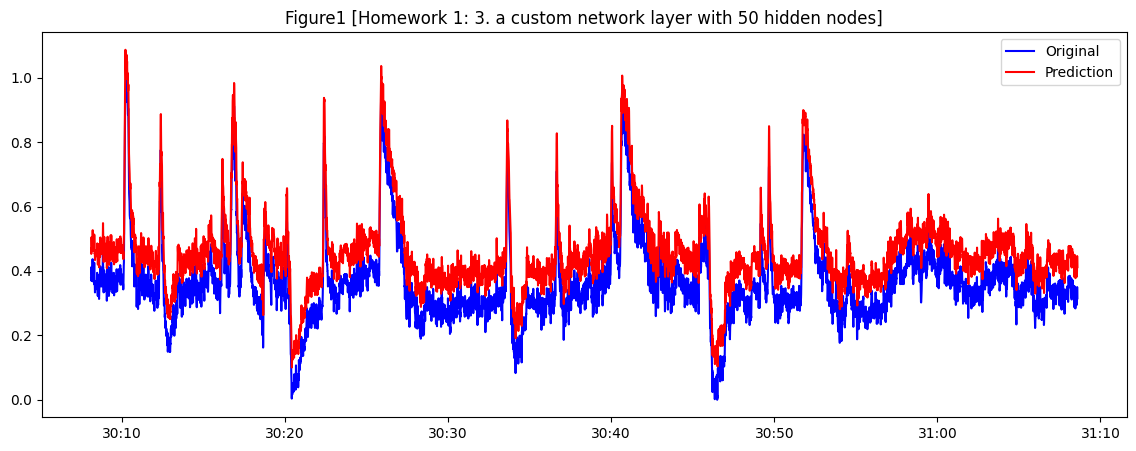

 91/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


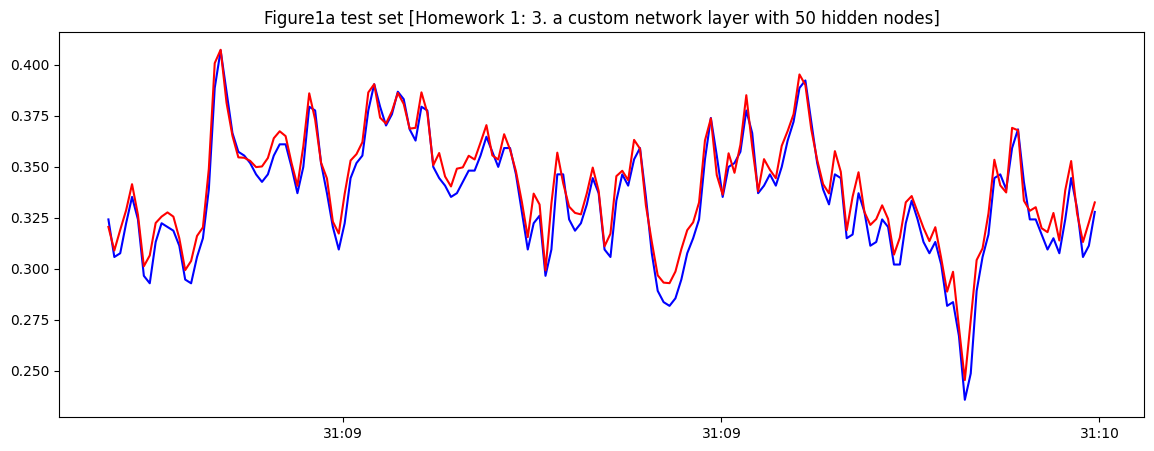

<Axes: title={'center': 'Figure3 [Homework 1: 3. a custom network layer with 50 hidden nodes]'}>

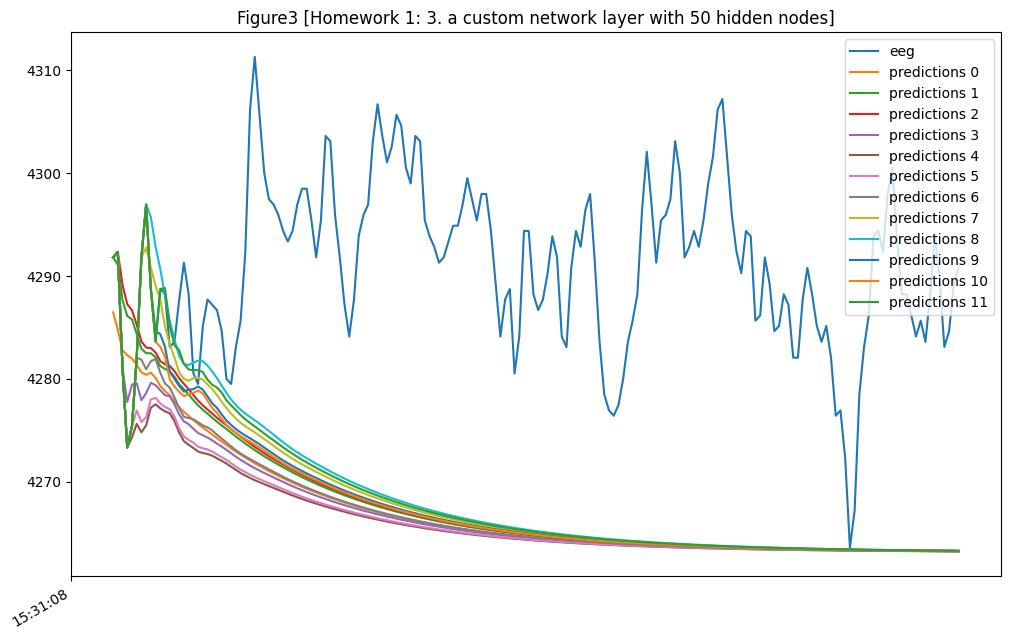

In [72]:
##HomeWork 1
## 3 a custom network layer with 50 hidden nodes [not really custom network but with leaky ReLu activation]
predict_length = 12
generator = TimeseriesGenerator(scaled_train, scaled_train, length = predict_length, batch_size=1)
n_features = 1  #this is the dimension of each sample x(t)


model = Sequential()
use_custom = 1
if use_custom == 1:
  model.add(Flatten(input_shape = (predict_length, n_features)))
  model.add(Dense(50, activation = 'leaky_relu'))
else:
  #if you don't flatten, will get a separate single-input net for each time value
  model.add(Flatten(input_shape = (predict_length, n_features)))
  model.add(Dense(50, activation = 'relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.fit(generator,epochs=5)
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

losses = pd.DataFrame(model.history.history)
losses.plot()

#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1 [Homework 1: 3. a custom network layer with 50 hidden nodes]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b', label='Original')
plt.plot(train_predict+0.1,'r', label='Prediction')
plt.legend()
plt.show()

validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set [Homework 1: 3. a custom network layer with 50 hidden nodes]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()

test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []
  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):
      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='Figure3 [Homework 1: 3. a custom network layer with 50 hidden nodes]')

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 0.0033
Epoch 2/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 8.8546e-04
Epoch 3/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - loss: 6.8897e-04
Epoch 4/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 18s 2ms/step - loss: 6.1341e-04
Epoch 5/5
7745/7745 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 5.6801e-04


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_11 (Flatten)            │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 30)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 20)             │           620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,095 (12.09 KB)

 Trainable params: 1,031 (4.03 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,064 (8.07 KB)

7745/7745 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


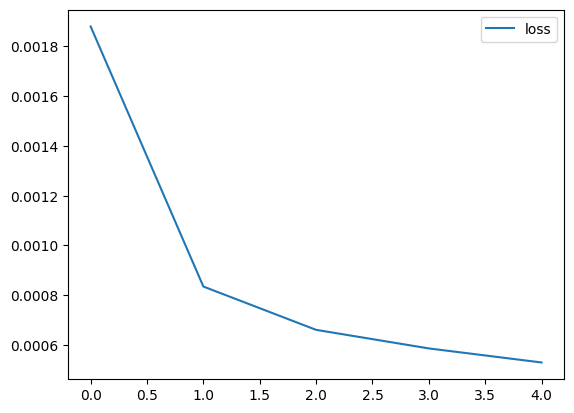

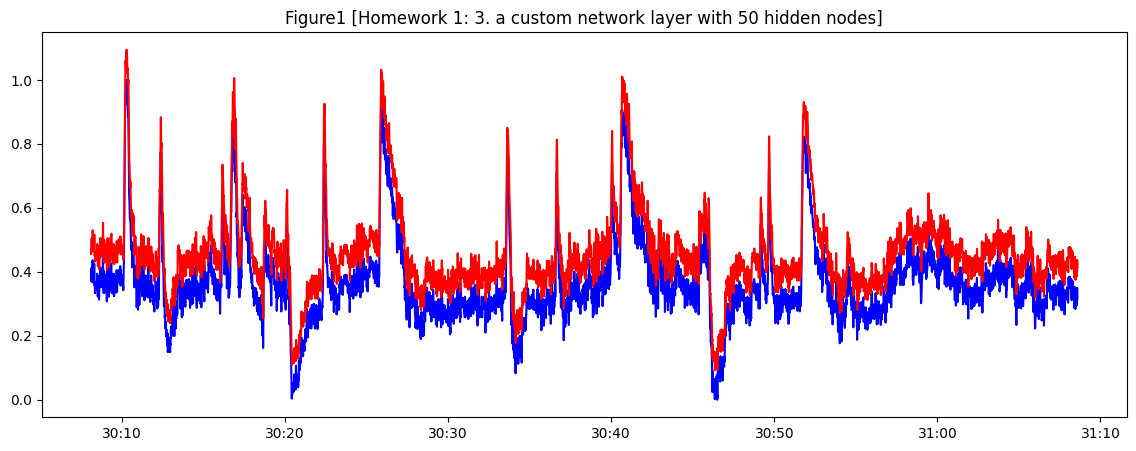

104/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


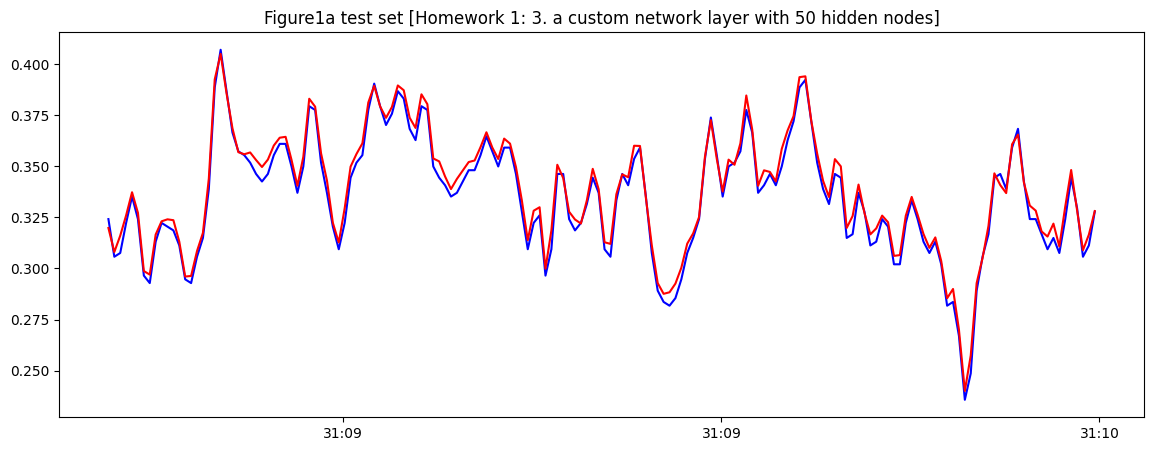

<Axes: title={'center': 'Figure3 [Homework 1: 3. a custom network layer with 50 hidden nodes]'}>

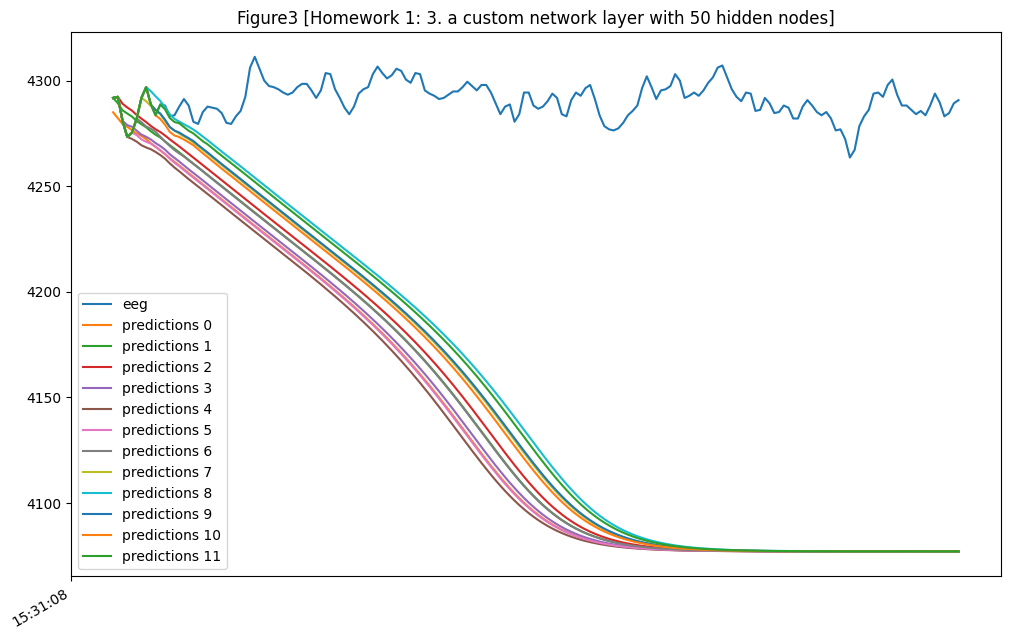

In [73]:
##HomeWork 1
## 3 a custom network layer with 50 hidden nodes
predict_length = 12
generator = TimeseriesGenerator(scaled_train, scaled_train, length = predict_length, batch_size=1)
n_features = 1  #this is the dimension of each sample x(t)
model = Sequential()
def custom_activation(x):
    return (K.sigmoid(x)*K.sigmoid(x))
model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(30, activation = custom_activation))
model.add(Dense(20, activation = custom_activation))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.fit(generator,epochs=5)
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length


losses = pd.DataFrame(model.history.history)
losses.plot()

train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1 [Homework 1: 3. a custom network layer with 50 hidden nodes]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b',label='Original')
plt.plot(train_predict+0.1,'r',label='Prediction')
plt.show()

validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set [Homework 1: 3. a custom network layer with 50 hidden nodes]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()

test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []
  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):
      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='Figure3 [Homework 1: 3. a custom network layer with 50 hidden nodes]')


Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7733/7733 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 0.0016
Epoch 2/5
7733/7733 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 7.5444e-04
Epoch 3/5
7733/7733 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 6.6167e-04
Epoch 4/5
7733/7733 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 6.0849e-04
Epoch 5/5
7733/7733 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 5.5229e-04


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_12 (Flatten)            │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 50)             │         1,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.26 KB)

 Trainable params: 1,301 (5.08 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,604 (10.18 KB)

7733/7733 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


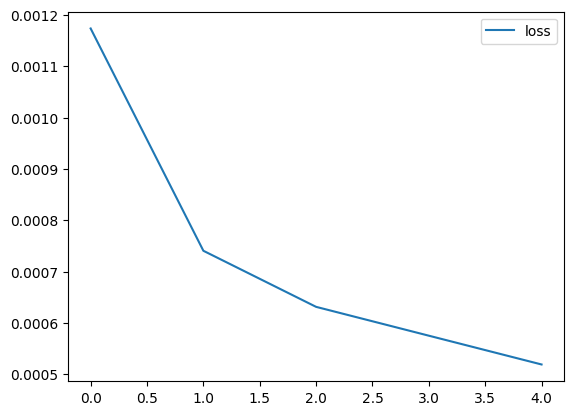

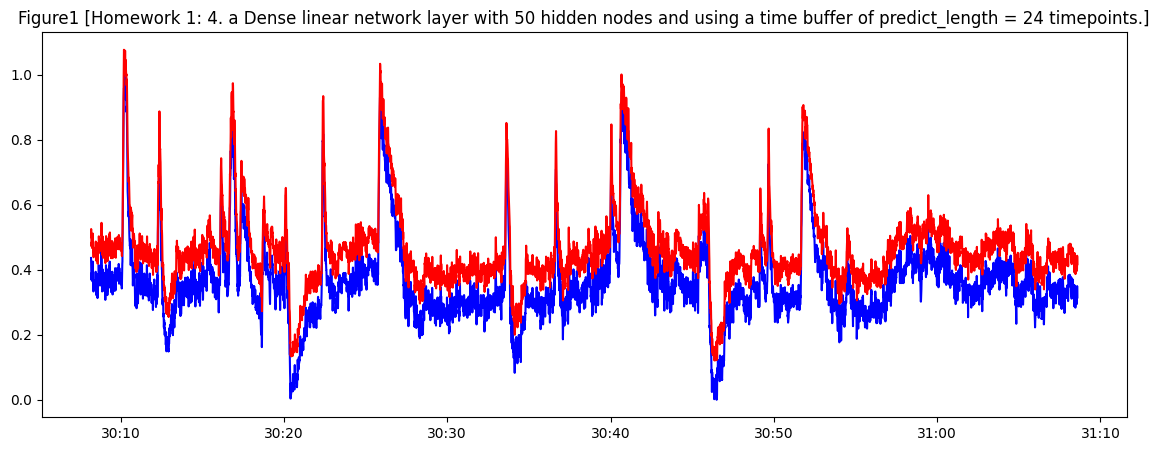

 69/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


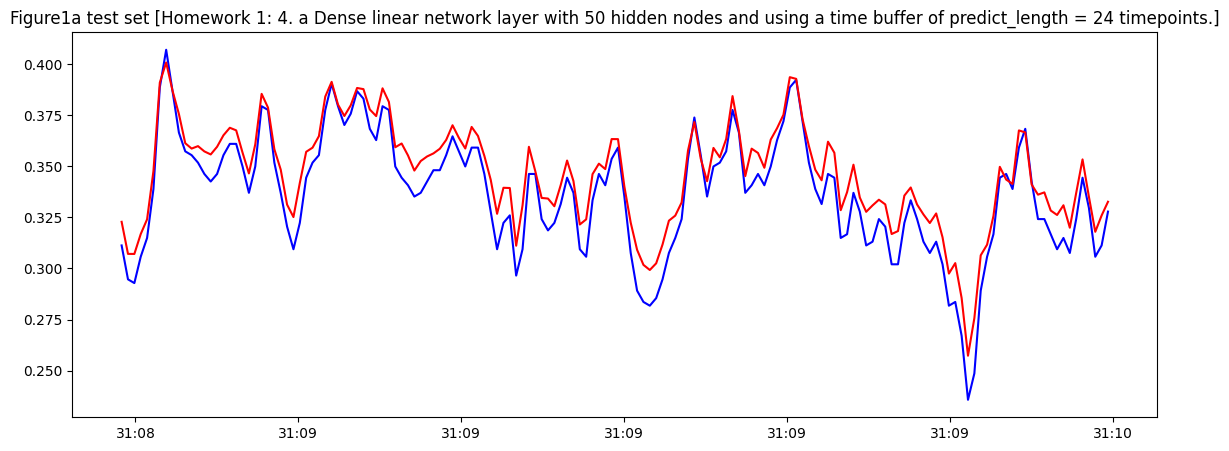

<Axes: title={'center': 'Figure3 [Homework 1: 4. a Dense linear network layer with 50 hidden nodes and using a time buffer of predict_length = 24 timepoints.]'}>

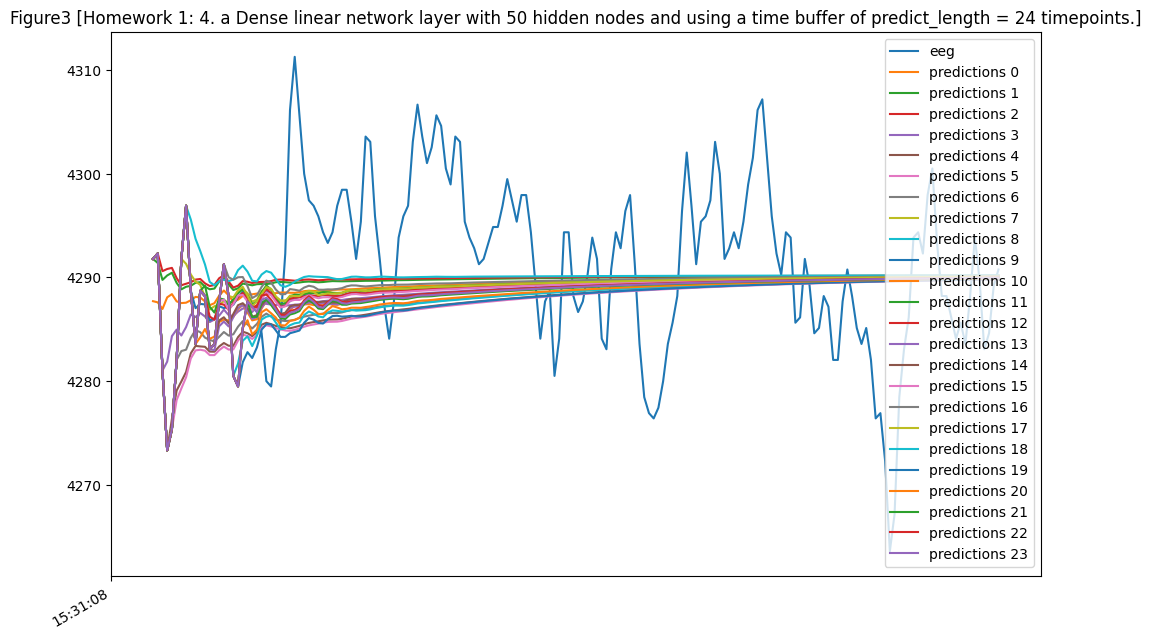

In [74]:
##HomeWork 1
## 4 a Dense linear network layer with 50 hidden nodes and using a time buffer of predict_length = 24 timepoints.
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

predict_length = 24
generator = TimeseriesGenerator(scaled_train, scaled_train, length = predict_length, batch_size=1)

model = Sequential()  #method to build the network from the bottom, one layer at a time
model.add(Flatten(input_shape = (predict_length, n_features)))  #defines the shape of the input
model.add(Dense(50, activation = 'relu'))
model.add(Dense(1))  #single output linear unit is the top layer
model.compile(optimizer='adam', loss='mse')  #specify the cost function and the descent rule
model.fit(generator,epochs=5)
model.summary()  #show the model layer sizes


losses = pd.DataFrame(model.history.history)
losses.plot()

#get the model predictions for all timepoints
predicted_outputs = model.predict(generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
train_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=train.index[predict_length:])
train_orig = pd.DataFrame(data=scaled_train[predict_length:], columns=['eeg'], index=train.index[predict_length:len(scaled_train)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1 [Homework 1: 4. a Dense linear network layer with 50 hidden nodes and using a time buffer of predict_length = 24 timepoints.]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(train_orig,'b')
plt.plot(train_predict+0.1,'r')
plt.show()


validation_generator = TimeseriesGenerator(scaled_test,scaled_test, length=predict_length, batch_size=1)

#get the model predictions for all timepoints
#this time, do it on the test set rather than the training set
predicted_outputs = model.predict(validation_generator)
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
test_predict = pd.DataFrame(data=predicted_outputs, columns=['eeg'], index=test.index[predict_length:])
test_orig = pd.DataFrame(data=scaled_test[predict_length-1:-1], columns=['eeg'], index=test.index[predict_length:len(scaled_test)])
plt.figure(figsize=(14,5),linewidth=1)
plt.title('Figure1a test set [Homework 1: 4. a Dense linear network layer with 50 hidden nodes and using a time buffer of predict_length = 24 timepoints.]')
ax = plt.gca()
ax.xaxis_date()
ax.xaxis.set_major_formatter(date_formatter)
plt.plot(test_orig,'b')
plt.plot(test_predict+0.01,'r')
plt.show()

test_predict = test.copy()
for t0 in range(predict_length):
  test_predictions = []
  if t0>0:
    first_eval_batch = np.append(scaled_train[-(predict_length-t0):],scaled_test[:t0])
  else:
    first_eval_batch = scaled_train[-predict_length:]
  current_batch = first_eval_batch.reshape((1, predict_length, n_features))

  for i in range(len(test)-t0):
      # get prediction 1 time stamp ahead ([0] is for grabbing just the number instead of [array])
      current_pred = model.predict(current_batch, verbose=0)[0]

      # store prediction
      test_predictions.append(current_pred)

      # update batch to now include prediction and drop first value
      current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

  if t0>0:
    test_predictions = np.append(scaled_test[:t0], test_predictions, axis=0)
  scaled_predictions = scaler.inverse_transform(test_predictions)
  test_predict[f'predictions {t0}']= scaled_predictions
test_predict.plot(figsize=(12,8),title='Figure3 [Homework 1: 4. a Dense linear network layer with 50 hidden nodes and using a time buffer of predict_length = 24 timepoints.]')